# Random Forest - Predicting Obesity Level

Goal: predict `obesity_level` (7 classes) from lifestyle habits. 

### Step 1: Import libraries

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path
from scipy.stats import randint
from sklearn.model_selection import train_test_split, cross_validate, RandomizedSearchCV
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix, ConfusionMatrixDisplay

### Step 2: Load data and remove duplicates


In [ ]:
data_path = "../data/clean_data/cleaned_obesity_data.csv"
df = pd.read_csv(data_path)
df = df.drop_duplicates()
df.shape

(2087, 17)

: 

### Step 3: Choose features (X) and target (y)
Dropping Height and Weight because the obesity level is calculated from BMI (weight / height²).
Keeping them would make the prediction too easy.

In [3]:
X = df.drop(columns=["obesity_level", "Height", "Weight"])
y = df["obesity_level"]

In [4]:
X = pd.get_dummies(X, columns=["Gender", "CAEC", "CALC", "MTRANS"], drop_first=True, dtype=int)
X.head()

,Age,family_history_with_overweight,FAVC,FCVC,NCP,SMOKE,CH2O,SCC,FAF,TUE,...,CAEC_Frequently,CAEC_Sometimes,CAEC_no,CALC_Frequently,CALC_Sometimes,CALC_no,MTRANS_Bike,MTRANS_Motorbike,MTRANS_Public_Transportation,MTRANS_Walking
0,21.0,1,0,2.0,3.0,0,2.0,0,0.0,1.0,...,0,1,0,0,0,1,0,0,1,0
1,21.0,1,0,3.0,3.0,1,3.0,1,3.0,0.0,...,0,1,0,0,1,0,0,0,1,0
2,23.0,1,0,2.0,3.0,0,2.0,0,2.0,1.0,...,0,1,0,1,0,0,0,0,1,0
3,27.0,0,0,3.0,3.0,0,2.0,0,2.0,0.0,...,0,1,0,1,0,0,0,0,0,1
4,22.0,0,0,2.0,1.0,0,2.0,0,0.0,0.0,...,0,1,0,0,1,0,0,0,1,0


In [5]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, stratify=y, random_state=42)
print("Train:", X_train.shape, "Test:", X_test.shape)

Train: (1669, 21) Test: (418, 21)


In [6]:
rf = RandomForestClassifier(random_state=42)

scores = cross_validate(rf, X_train, y_train, cv=10, scoring=["accuracy", "f1_macro"])
print("Accuracy per fold:", scores["test_accuracy"].round(3))
print("Mean accuracy: %.3f (+/- %.3f)" % (scores["test_accuracy"].mean(), scores["test_accuracy"].std()))
print("Mean macro F1: %.3f (+/- %.3f)" % (scores["test_f1_macro"].mean(), scores["test_f1_macro"].std()))

Accuracy per fold: [0.85  0.838 0.814 0.832 0.88  0.904 0.814 0.862 0.868 0.855]
Mean accuracy: 0.852 (+/- 0.027)
Mean macro F1: 0.849 (+/- 0.028)


### Step 7: Tune hyperparameters with RandomizedSearchCV


In [7]:
param_dist = {
    "n_estimators": randint(100, 500),      # number of trees
    "max_depth": [None, 10, 15, 20, 30],    # how deep each tree can grow
    "min_samples_split": randint(2, 11),    # min rows needed to split a node
}

search = RandomizedSearchCV(rf, param_distributions=param_dist, n_iter=20, cv=10,
                            scoring="f1_macro", random_state=42, n_jobs=-1)
search.fit(X_train, y_train)

print("Best settings:", search.best_params_)
print("Best CV macro F1: %.3f" % search.best_score_)

Best settings: {'max_depth': 15, 'min_samples_split': 4, 'n_estimators': 463}
Best CV macro F1: 0.860


### Step 8: Test the best model on the test set

In [8]:
best_rf = search.best_estimator_
y_pred = best_rf.predict(X_test)

print("Test accuracy: %.3f" % accuracy_score(y_test, y_pred))
print()
print(classification_report(y_test, y_pred))

Test accuracy: 0.849

                     precision    recall  f1-score   support

Insufficient_Weight       0.88      0.94      0.91        53
      Normal_Weight       0.69      0.74      0.71        57
     Obesity_Type_I       0.84      0.89      0.86        70
    Obesity_Type_II       0.90      0.95      0.93        60
   Obesity_Type_III       1.00      0.98      0.99        65
 Overweight_Level_I       0.81      0.71      0.76        55
Overweight_Level_II       0.80      0.71      0.75        58

           accuracy                           0.85       418
          macro avg       0.85      0.85      0.84       418
       weighted avg       0.85      0.85      0.85       418



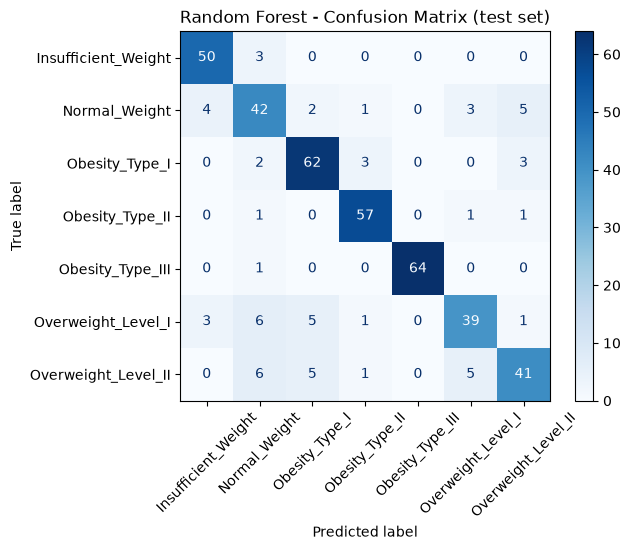

In [ ]:
cm = confusion_matrix(y_test, y_pred)
ConfusionMatrixDisplay(cm, display_labels=best_rf.classes_).plot(xticks_rotation=45, cmap="Blues")
plt.title("random forest - confusion matrix (test set)")
plt.show()

### Step 9: Feature importance


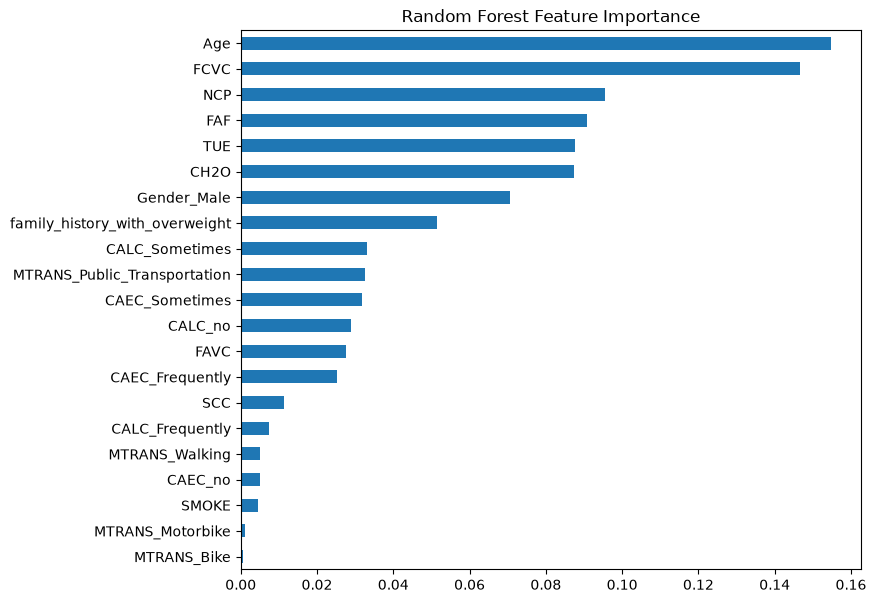

In [10]:
importance = pd.Series(best_rf.feature_importances_, index=X_train.columns).sort_values()
importance.plot(kind="barh", figsize=(8, 7), title="Random Forest Feature Importance")
plt.show()